In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 0. Load Locally Downloaded Dataset File
# ---------------------------------------------------------
# When downloaded from UCI (ID: 236), the file is typically named `seeds_dataset.txt`
# and uses whitespace/tabs as delimiters with no header row.
file_path = Path("seeds_dataset.txt")

columns = [
    "Area",
    "Perimeter",
    "Compactness",
    "Kernel_length",
    "Kernel_width",
    "Asymmetry_coefficient",
    "Kernel_groove_length",
    "Variety",
]

# Read whitespace-separated file; if you saved a comma-separated CSV with headers,
# use `pd.read_csv("seeds.csv")` instead.
df = pd.read_csv(file_path, sep=r"\s+", header=None, names=columns)

# Optional: map numeric variety codes (1, 2, 3) to cultivar names for readability
variety_map = {1: "Kama (1)", 2: "Rosa (2)", 3: "Canadian (3)"}
df["Variety_name"] = df["Variety"].map(variety_map)

# ---------------------------------------------------------
# Common Requirements: Structural Inspection
# ---------------------------------------------------------
print("=== HEAD (First 5 rows) ===")
print(df.head())

print("\n=== TAIL (Last 5 rows) ===")
print(df.tail())

print("\n=== SHAPE (Rows, Columns) ===")
print(df.shape)

print("\n=== INFO ===")
print(df.info())

print("\n=== DESCRIBE ===")
print(df.describe())
# ---------------------------------------------------------
# Q1: How Many Samples Belong to Each Variety?
# ---------------------------------------------------------
print("\n=== Q1: SAMPLE COUNT PER VARIETY ===")
variety_counts = df["Variety_name"].value_counts()
print(variety_counts)

# ---------------------------------------------------------
# Q5: Check for Missing Values and Duplicates
# ---------------------------------------------------------
print("\n=== Q5: MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())
print("Total missing values:", int(df.isnull().sum().sum()))

print("\n=== Q5: DUPLICATE RECORDS ===")
num_duplicates = int(df.duplicated().sum())
print("Number of exact duplicate rows:", num_duplicates)











=== HEAD (First 5 rows) ===
    Area  Perimeter  Compactness  Kernel_length  Kernel_width  \
0  15.26      14.84       0.8710          5.763         3.312   
1  14.88      14.57       0.8811          5.554         3.333   
2  14.29      14.09       0.9050          5.291         3.337   
3  13.84      13.94       0.8955          5.324         3.379   
4  16.14      14.99       0.9034          5.658         3.562   

   Asymmetry_coefficient  Kernel_groove_length  Variety Variety_name  
0                  2.221                 5.220        1     Kama (1)  
1                  1.018                 4.956        1     Kama (1)  
2                  2.699                 4.825        1     Kama (1)  
3                  2.259                 4.805        1     Kama (1)  
4                  1.355                 5.175        1     Kama (1)  

=== TAIL (Last 5 rows) ===
      Area  Perimeter  Compactness  Kernel_length  Kernel_width  \
205  12.19      13.20       0.8783          5.137         2.

In [ ]:
# ---------------------------------------------------------
# Q2: Mean, Median, Min & Max for Area, Perimeter & Length (NumPy)
# ---------------------------------------------------------
print("\n=== Q2: KERNEL AREA, PERIMETER & LENGTH STATISTICS (NUMPY) ===")
for col in ["Area", "Perimeter", "Kernel_length"]:
    arr = df[col].to_numpy()
    print(f"\n{col}:")
    print(f"  Mean:    {np.mean(arr):.4f}")
    print(f"  Median:  {np.median(arr):.4f}")
    print(f"  Minimum: {np.min(arr):.4f}")
    print(f"  Maximum: {np.max(arr):.4f}")



=== Q2: KERNEL AREA, PERIMETER & LENGTH STATISTICS (NUMPY) ===

Area:
  Mean:    14.8475
  Median:  14.3550
  Minimum: 10.5900
  Maximum: 21.1800

Perimeter:
  Mean:    14.5593
  Median:  14.3200
  Minimum: 12.4100
  Maximum: 17.2500

Kernel_length:
  Mean:    5.6285
  Median:  5.5235
  Minimum: 4.8990
  Maximum: 6.6750


In [ ]:
# ---------------------------------------------------------
# Q3: Which Variety Has the Highest Average Area and Width?
# ---------------------------------------------------------
variety_area_width = df.groupby("Variety_name")[["Area", "Kernel_width"]].mean()
top_area_variety = variety_area_width["Area"].idxmax()
top_width_variety = variety_area_width["Kernel_width"].idxmax()

print("\n=== Q3: AVERAGE AREA & WIDTH BY VARIETY ===")
print(variety_area_width)
print(
    f"Highest Average Area Variety:  {top_area_variety} "
    f"({variety_area_width.loc[top_area_variety, 'Area']:.4f})"
)
print(
    f"Highest Average Width Variety: {top_width_variety} "
    f"({variety_area_width.loc[top_width_variety, 'Kernel_width']:.4f})"
)


=== Q3: AVERAGE AREA & WIDTH BY VARIETY ===
                   Area  Kernel_width
Variety_name                         
Canadian (3)  11.873857      2.853771
Kama (1)      14.334429      3.244629
Rosa (2)      18.334286      3.677414
Highest Average Area Variety:  Rosa (2) (18.3343)
Highest Average Width Variety: Rosa (2) (3.6774)


In [ ]:
# ---------------------------------------------------------
# Q4: Sort Records by Kernel Area and Show Top 10
# ---------------------------------------------------------
# Also demonstrating Pandas filtering (e.g., filtering records above median area before taking top 10)
median_area = np.median(df["Area"].to_numpy())
filtered_above_median = df[df["Area"] > median_area]
top_10_area = filtered_above_median.sort_values(by="Area", ascending=False).head(10)

print("\n=== Q4: TOP 10 RECORDS BY KERNEL AREA ===")
print(top_10_area[["Variety_name", "Area", "Perimeter", "Kernel_length", "Kernel_width"]])


=== Q4: TOP 10 RECORDS BY KERNEL AREA ===
    Variety_name   Area  Perimeter  Kernel_length  Kernel_width
88      Rosa (2)  21.18      17.21          6.573         4.033
114     Rosa (2)  20.97      17.25          6.563         3.991
89      Rosa (2)  20.88      17.05          6.450         4.032
77      Rosa (2)  20.71      17.23          6.579         3.814
120     Rosa (2)  20.24      16.91          6.315         3.962
82      Rosa (2)  20.20      16.89          6.285         3.864
128     Rosa (2)  20.16      17.03          6.513         3.773
90      Rosa (2)  20.10      16.99          6.581         3.785
119     Rosa (2)  20.03      16.90          6.493         3.857
108     Rosa (2)  19.94      16.92          6.675         3.763


In [ ]:
# ---------------------------------------------------------
# Q5: Check for Missing Values and Duplicates
# ---------------------------------------------------------
print("\n=== Q5: MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())
print("Total missing values:", int(df.isnull().sum().sum()))

print("\n=== Q5: DUPLICATE RECORDS ===")
num_duplicates = int(df.duplicated().sum())
print("Number of exact duplicate rows:", num_duplicates)



=== Q5: MISSING VALUES PER COLUMN ===
Area                     0
Perimeter                0
Compactness              0
Kernel_length            0
Kernel_width             0
Asymmetry_coefficient    0
Kernel_groove_length     0
Variety                  0
Variety_name             0
dtype: int64
Total missing values: 0

=== Q5: DUPLICATE RECORDS ===
Number of exact duplicate rows: 0



=== Q6: AVERAGE MEASUREMENTS ACROSS ALL THREE VARIETIES ===
                   Area  Perimeter  Compactness  Kernel_length  Kernel_width  \
Variety_name                                                                   
Canadian (3)  11.873857  13.247857     0.849409       5.229514      2.853771   
Kama (1)      14.334429  14.294286     0.880070       5.508057      3.244629   
Rosa (2)      18.334286  16.135714     0.883517       6.148029      3.677414   

              Asymmetry_coefficient  Kernel_groove_length  
Variety_name                                               
Canadian (3)               4.788400              5.116400  
Kama (1)                   2.667403              5.087214  
Rosa (2)                   3.644800              6.020600  


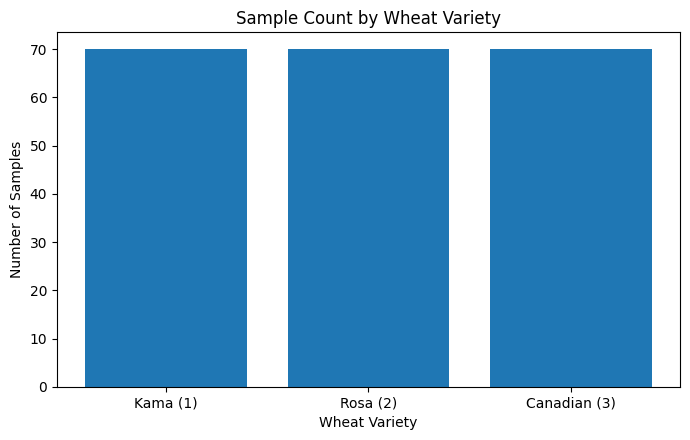

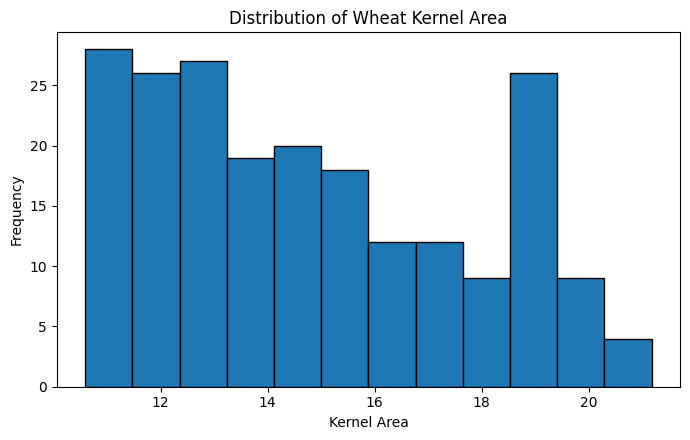

In [ ]:
# ---------------------------------------------------------
# Q6: Compare Average Measurements Across the Three Varieties
# ---------------------------------------------------------
numeric_features = [
    "Area",
    "Perimeter",
    "Compactness",
    "Kernel_length",
    "Kernel_width",
    "Asymmetry_coefficient",
    "Kernel_groove_length",
]
variety_comparison = df.groupby("Variety_name")[numeric_features].mean()

print("\n=== Q6: AVERAGE MEASUREMENTS ACROSS ALL THREE VARIETIES ===")
print(variety_comparison)

# ---------------------------------------------------------
# Visualizations: (1) Variety-Count Bar Chart & (2) Area Histogram
# ---------------------------------------------------------
# Chart 1: Variety-Count Bar Chart
plt.figure(figsize=(7, 4.5))
plt.bar(variety_counts.index, variety_counts.values)
plt.title("Sample Count by Wheat Variety")
plt.xlabel("Wheat Variety")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# Chart 2: Kernel Area Histogram
area_arr = df["Area"].to_numpy()
plt.figure(figsize=(7, 4.5))
plt.hist(area_arr, bins=12, edgecolor="black")
plt.title("Distribution of Wheat Kernel Area")
plt.xlabel("Kernel Area")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



















